<img src="https://cdn.pixabay.com/photo/2015/04/09/16/39/indonesia-714747_960_720.png" width=150 height=130 align=center />

# Analisis Peta Kebakaran Hutan di Indonesia dengan Python

Notebook ini menganalisis **titik-titik kebakaran hutan (hotspot) terkini di Indonesia** menggunakan GeoPandas, mulai dari pencarian dataset, penentuan CRS, pembuatan peta choropleth, hingga desain layout peta lengkap (legenda, North arrow, skala, judul).

| | |
|---|---|
| **Nama** | Kayla Aprilia |
| **NIM** | 52250057 |

---
## 0. Import Library
Library utama: `pandas` (tabel), `geopandas` (data spasial), dan `matplotlib` (visualisasi peta).

In [1]:
import os
import io
import requests
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

print("GeoPandas versi:", gpd.__version__)

GeoPandas versi: 1.2.0


---
## 1. Mencari Dataset Terkini Titik Kebakaran Hutan (dengan Geometry Longitude & Latitude)

**Sumber dataset:** [NASA FIRMS (Fire Information for Resource Management System)](https://firms.modaps.eosdis.nasa.gov/active_fire/), produk *VIIRS 375 m Active Fire*. Data diunduh melalui *Archive Download* FIRMS (https://firms.modaps.eosdis.nasa.gov/download/) berupa file NRT (*near real-time*) VIIRS S-NPP. File hasil unduhan tersebut disimpan sebagai salinan di GitHub (URL pada sel di bawah) agar notebook dapat dijalankan ulang tanpa akun FIRMS.

Setiap baris dataset adalah satu titik panas (*hotspot*) dengan kolom `latitude` dan `longitude`, yang akan dijadikan geometry titik (`Point`).

In [2]:
# Sumber  : NASA FIRMS | VIIRS S-NPP 375 m (NRT) | wilayah Indonesia
# URL     : https://firms.modaps.eosdis.nasa.gov/download/
# Periode : 27 Oktober 2026 - 2 November 2026
url_dipakai = "https://raw.githubusercontent.com/kayieeela/Dataset_hotspot_nrt_2026-10-27_sd_2026-11-02/refs/heads/main/hotspot_nrt_2026-10-27_sd_2026-11-02.csv"

df_raw = pd.read_csv(url_dipakai, dtype={"acq_time": str})

print("URL dataset yang dipakai:", url_dipakai)
print("Jumlah baris data mentah:", len(df_raw))
df_raw.head()

URL dataset yang dipakai: https://raw.githubusercontent.com/kayieeela/Dataset_hotspot_nrt_2026-10-27_sd_2026-11-02/refs/heads/main/hotspot_nrt_2026-10-27_sd_2026-11-02.csv
Jumlah baris data mentah: 12779


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-7.79629,140.65822,337.22,0.60,0.71,2026-10-27,0332,SNPP,SNPP,n,2.0NRT,289.94,7.52,D
1,-7.82868,140.59605,332.15,0.61,0.71,2026-10-27,0332,SNPP,SNPP,n,2.0NRT,290.33,5.86,D
2,-7.82796,140.60175,334.71,0.61,0.71,2026-10-27,0332,SNPP,SNPP,n,2.0NRT,288.30,7.37,D
3,-7.91940,139.93102,343.03,0.68,0.74,2026-10-27,0332,SNPP,SNPP,n,2.0NRT,289.82,12.63,D
4,-7.84059,140.66066,339.71,0.60,0.71,2026-10-27,0332,SNPP,SNPP,n,2.0NRT,291.87,12.42,D


In [3]:
# Pastikan dataset memiliki informasi geometry (longitude & latitude) yang valid
print("Kolom tersedia :", list(df_raw.columns))
print("Ada longitude  :", "longitude" in df_raw.columns)
print("Ada latitude   :", "latitude" in df_raw.columns)

df = df_raw.dropna(subset=["longitude", "latitude"]).copy()
valid = df["longitude"].between(-180, 180) & df["latitude"].between(-90, 90)
print("Baris dengan koordinat valid:", int(valid.sum()), "dari", len(df_raw))
df = df[valid]

# Saring data hanya di sekitar wilayah Indonesia (bounding box kasar)
df = df[df["longitude"].between(94, 142) & df["latitude"].between(-12, 7)]

# Buang deteksi berkeyakinan rendah ('l' = low) untuk mengurangi false alarm (khusus VIIRS)
if "confidence" in df.columns and not pd.api.types.is_numeric_dtype(df["confidence"]):
    df = df[df["confidence"].astype(str).str.lower() != "l"]

print("Jumlah titik panas setelah penyaringan awal:", len(df))

# Rentang waktu pengamatan
tgl_awal, tgl_akhir = df["acq_date"].min(), df["acq_date"].max()
print("Periode data:", tgl_awal, "s.d.", tgl_akhir)

# Simpan salinan dataset sebagai CSV
nama_csv = f"dataset_hotspot_indonesia_{tgl_akhir}.csv"
df.to_csv(nama_csv, index=False)
print("Dataset tersimpan:", nama_csv)

Kolom tersedia : ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight']
Ada longitude  : True
Ada latitude   : True
Baris dengan koordinat valid: 12779 dari 12779
Jumlah titik panas setelah penyaringan awal: 12096
Periode data: 2026-10-27 s.d. 2026-11-02
Dataset tersimpan: dataset_hotspot_indonesia_2026-11-02.csv


---
## 2. Menentukan Sistem CRS (EPSG)

| Kebutuhan | CRS | Alasan |
|---|---|---|
| Data titik panas (FIRMS) & batas provinsi | **EPSG:4326** (WGS84 lon/lat) | CRS asli dataset, koordinat dalam derajat |
| Tampilan peta akhir | **EPSG:3857** (Web Mercator) | Satuan meter sehingga skala bar bisa digambar |
| Perhitungan luas wilayah | **EPSG:6933** (World Cylindrical Equal Area) | Proyeksi *equal-area*, luas lebih akurat daripada Web Mercator |

Titik panas diubah menjadi `GeoDataFrame` dengan `points_from_xy()`. Karena data berupa lon/lat, CRS awalnya **ditetapkan** dengan `crs="EPSG:4326"` (setara `set_crs`, tidak mengubah koordinat). Perubahan ke CRS lain dilakukan dengan `to_crs()`.

In [4]:
# Membuat geometry titik dari kolom longitude & latitude
hotspot = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"]),
    crs="EPSG:4326"
)

print(type(hotspot))
print("Tipe geometri:", hotspot.geom_type.unique())
print("CRS titik panas:", hotspot.crs)
hotspot[["acq_date", "latitude", "longitude", "geometry"]].head(3)

<class 'geopandas.geodataframe.GeoDataFrame'>
Tipe geometri: ['Point']
CRS titik panas: EPSG:4326


,acq_date,latitude,longitude,geometry
0,2026-10-27,-7.79629,140.65822,POINT (140.65822 -7.79629)
1,2026-10-27,-7.82868,140.59605,POINT (140.59605 -7.82868)
2,2026-10-27,-7.82796,140.60175,POINT (140.60175 -7.82796)


---
## 3. Membaca Batas Provinsi Indonesia & Reproyeksi

Choropleth membutuhkan **poligon wilayah**. Titik panas akan dihitung per provinsi menggunakan batas administrasi provinsi Indonesia (GeoJSON dari GitHub).

In [5]:
# URL batas provinsi Indonesia (GeoJSON)
URL_PROVINSI = "https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/master/indonesia-prov.geojson"
FILE_PROVINSI = "indonesia-prov.geojson"

if not os.path.exists(FILE_PROVINSI):
    r = requests.get(URL_PROVINSI, timeout=120)
    r.raise_for_status()
    with open(FILE_PROVINSI, "wb") as f:
        f.write(r.content)

# on_invalid='ignore' untuk melewati kesalahan ring yang tidak tertutup
prov = gpd.read_file(FILE_PROVINSI, on_invalid="ignore")
prov["geometry"] = prov.geometry.buffer(0)   # perbaiki geometri yang tidak valid

# Pastikan CRS terdefinisi
if prov.crs is None:
    prov = prov.set_crs(epsg=4326)

print("Jumlah provinsi:", len(prov))
print("CRS batas provinsi:", prov.crs)
prov[["Propinsi", "geometry"]].head(3)

Jumlah provinsi: 34
CRS batas provinsi: EPSG:4326


,Propinsi,geometry
0,NUSATENGGARA BARAT,"MULTIPOLYGON (((117.6272 -8.5064, 117.6347 -8...."
1,GORONTALO,"POLYGON ((122.18814 1.0453, 122.22627 1.00335,..."
2,SULAWESI TENGGARA,"MULTIPOLYGON (((124.07579 -5.99996, 123.9874 -..."


CRS peta akhir: EPSG:3857


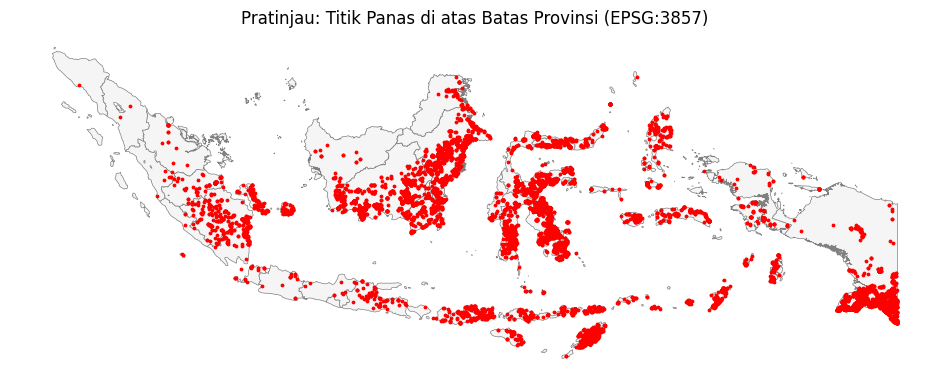

In [6]:
# Reproyeksi dengan to_crs()
prov_3857 = prov.to_crs(epsg=3857)          # untuk tampilan peta
hotspot_3857 = hotspot.to_crs(epsg=3857)

# Luas wilayah (km2) dihitung di CRS equal-area EPSG:6933
prov["Luas_km2"] = prov.to_crs(epsg=6933).geometry.area / 1e6

print("CRS peta akhir:", prov_3857.crs)
fig, ax = plt.subplots(figsize=(12, 5))
prov_3857.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
hotspot_3857.plot(ax=ax, color="red", markersize=3)
ax.set_title("Pratinjau: Titik Panas di atas Batas Provinsi (EPSG:3857)")
ax.set_axis_off()
plt.show()

---
## 4. Spatial Join & Normalisasi Data

Setiap titik panas dihubungkan ke provinsi tempatnya berada (*point-in-polygon* dengan `sjoin`), lalu dihitung:
- **Jumlah titik panas** per provinsi
- **Kepadatan titik panas** per 1.000 km² (normalisasi terhadap luas wilayah, agar perbandingan antarprovinsi adil)

In [7]:
# Spatial join point-in-polygon (dilakukan di CRS yang sama: EPSG:4326)
joined = gpd.sjoin(hotspot, prov[["Propinsi", "geometry"]], how="inner", predicate="within")
print(f"Titik panas di dalam batas provinsi: {len(joined)} dari {len(hotspot)}")
print(f"Titik di luar poligon (laut/perbatasan, tidak dihitung): {len(hotspot) - len(joined)}")

# Hitung jumlah titik panas per provinsi
jumlah = joined.groupby("Propinsi").size().rename("Jumlah_Titik_Panas")
prov = prov.merge(jumlah, on="Propinsi", how="left")
prov["Jumlah_Titik_Panas"] = prov["Jumlah_Titik_Panas"].fillna(0).astype(int)

# Normalisasi: kepadatan titik panas per 1.000 km2
prov["Kepadatan_per_1000km2"] = prov["Jumlah_Titik_Panas"] / prov["Luas_km2"] * 1000

# Samakan urutan dengan prov_3857 (hasil to_crs tidak mengubah urutan baris)
prov_3857 = prov_3857.merge(
    prov[["Propinsi", "Luas_km2", "Jumlah_Titik_Panas", "Kepadatan_per_1000km2"]], on="Propinsi"
)

# 10 provinsi dengan titik panas terbanyak
prov[["Propinsi", "Jumlah_Titik_Panas", "Luas_km2", "Kepadatan_per_1000km2"]] \
    .sort_values("Jumlah_Titik_Panas", ascending=False).head(10).reset_index(drop=True)

Titik panas di dalam batas provinsi: 11953 dari 12096
Titik di luar poligon (laut/perbatasan, tidak dihitung): 143


,Propinsi,Jumlah_Titik_Panas,Luas_km2,Kepadatan_per_1000km2
0,PAPUA,3040,313668.996550,9.691745
1,KALIMANTAN TIMUR,1527,126173.410588,12.102391
2,KALIMANTAN TENGAH,1280,154177.485411,8.302120
3,SULAWESI TENGGARA,1012,36287.981095,27.888022
4,SULAWESI TENGAH,982,59483.844476,16.508684
5,SULAWESI SELATAN,636,46005.456106,13.824447
6,NUSA TENGGARA TIMUR,631,45887.556346,13.751005
7,MALUKU,569,45082.797341,12.621222
8,KALIMANTAN SELATAN,325,36756.543092,8.841963
9,SUMATERA SELATAN,273,86296.705762,3.163504


---
## 5. Peta Choropleth & Desain Layout Peta

Peta choropleth menggunakan skema warna **sequential** (`YlOrRd`): semakin tua warna, semakin tinggi kepadatan titik panas. Skala warna memakai `PowerNorm` agar perbedaan nilai kecil tetap terlihat (akibatnya jarak antar-angka pada colorbar tidak linear). Titik-titik hitam menunjukkan **lokasi** tiap titik panas. Elemen layout: judul, subjudul periode, legenda (colorbar dan simbol titik), North arrow, skala bar, dan keterangan sumber data.

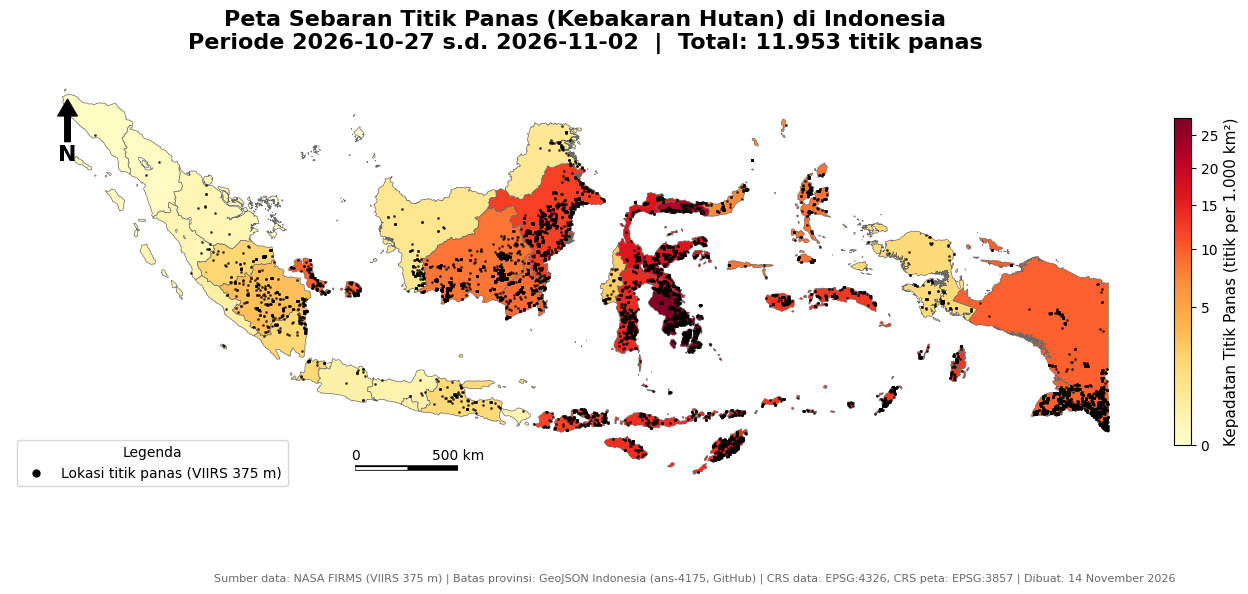

Peta tersimpan: Peta_Kebakaran_Hutan_Indonesia.png dan .jpeg


In [8]:
# ===== PETA AKHIR =====
kolom = "Kepadatan_per_1000km2"
vmax = max(float(prov_3857[kolom].max()), 1e-6)
norm = PowerNorm(gamma=0.5, vmin=0, vmax=vmax)
cmap = plt.get_cmap("YlOrRd")

fig, ax = plt.subplots(figsize=(14, 6))

# Layer 1: choropleth per provinsi
prov_3857.plot(ax=ax, color=cmap(norm(prov_3857[kolom].values)),
               edgecolor="dimgrey", linewidth=0.5)

# Layer 2: lokasi titik panas
# Hanya titik yang masuk batas provinsi (sama dengan yang dihitung pada judul)
hotspot_plot = hotspot_3857.loc[joined.index]
hotspot_plot.plot(ax=ax, color="black", markersize=1.2, alpha=0.6)

# Judul & subjudul (format angka Indonesia: pemisah ribuan titik)
total_fmt = f"{len(joined):,}".replace(",", ".")
ax.set_title("Peta Sebaran Titik Panas (Kebakaran Hutan) di Indonesia\n"
             f"Periode {tgl_awal} s.d. {tgl_akhir}  |  Total: {total_fmt} titik panas",
             fontsize=16, pad=15, fontweight="bold")

# Legenda 1: colorbar choropleth
sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.01)
cbar.set_label("Kepadatan Titik Panas (titik per 1.000 km²)", fontsize=11)

# Legenda 2: simbol titik panas
ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor="black",
                          markersize=7, label="Lokasi titik panas (VIIRS 375 m)")],
          loc="lower left", frameon=True, fontsize=10, title="Legenda")

# North arrow
ax.annotate("N", xy=(0.05, 0.93), xytext=(0.05, 0.80), xycoords="axes fraction",
            arrowprops=dict(facecolor="black", width=4, headwidth=14),
            ha="center", va="center", fontsize=16, fontweight="bold")

# Skala bar 500 km (EPSG:3857 bersatuan meter; Indonesia dekat ekuator sehingga distorsi kecil)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
panjang = 500_000
x0 = xmin + 0.30 * (xmax - xmin)
y0 = ymin + 0.06 * (ymax - ymin)
ax.plot([x0, x0 + panjang], [y0, y0], color="black", linewidth=4, solid_capstyle="butt")
ax.plot([x0, x0 + panjang / 2], [y0, y0], color="white", linewidth=2, solid_capstyle="butt")
ax.text(x0, y0 + 0.02 * (ymax - ymin), "0", ha="center", fontsize=10)
ax.text(x0 + panjang, y0 + 0.02 * (ymax - ymin), "500 km", ha="center", fontsize=10)

# Keterangan sumber & CRS
fig.text(0.5, 0.02,
         f"Sumber data: NASA FIRMS (VIIRS 375 m) | Batas provinsi: GeoJSON Indonesia (ans-4175, GitHub) | "
         f"CRS data: EPSG:4326, CRS peta: EPSG:3857 | Dibuat: {pd.Timestamp.now():%d %B %Y}",
         ha="center", fontsize=8, color="dimgrey")

ax.set_axis_off()
plt.tight_layout(rect=[0, 0.04, 1, 1])

# Simpan peta dalam format PNG dan JPEG
plt.savefig("Peta_Kebakaran_Hutan_Indonesia.png", dpi=300, bbox_inches="tight")
plt.savefig("Peta_Kebakaran_Hutan_Indonesia.jpeg", dpi=300, bbox_inches="tight")
plt.show()
print("Peta tersimpan: Peta_Kebakaran_Hutan_Indonesia.png dan .jpeg")

---
## 6. Kesimpulan

**1. Dataset dan periode.** Analisis memakai data titik panas NASA FIRMS (VIIRS S-NPP 375 m, produk NRT) untuk periode **27 Oktober – 2 November 2026** (7 hari). Dari 12.779 deteksi mentah, setelah penyaringan (koordinat valid, bounding box Indonesia, dan pembuangan deteksi berkeyakinan rendah) tersisa 12.096 titik, dan 11.953 titik berada di dalam batas 34 provinsi. Sebanyak 143 titik berada di luar poligon (laut, wilayah perbatasan, atau negara tetangga) sehingga tidak dihitung.

**2. Sistem CRS.** Data titik panas dan batas provinsi memakai **EPSG:4326** (WGS84). Peta akhir ditampilkan dalam **EPSG:3857** (Web Mercator) dan luas wilayah dihitung dalam **EPSG:6933** (equal-area) agar kepadatan titik panas per 1.000 km² lebih akurat.

**3. Jumlah titik panas.** Papua memiliki titik panas terbanyak (3.040 titik, sekitar 25% dari total). Berikutnya Kalimantan Timur (1.527), Kalimantan Tengah (1.280), Sulawesi Tenggara (1.012), dan Sulawesi Tengah (982). Sepuluh provinsi teratas menyumbang 10.275 dari 11.953 titik (sekitar 86%), sehingga titik panas terkonsentrasi pada sebagian kecil provinsi.

**4. Kepadatan titik panas (setelah normalisasi luas).** Kepadatan tertinggi dimiliki Sulawesi Tenggara (27,89 titik per 1.000 km²), disusul Gorontalo (22,31), Sulawesi Tengah (16,51), Sulawesi Selatan (13,82), dan Nusa Tenggara Timur (13,75). Papua memiliki jumlah terbanyak tetapi kepadatannya hanya 9,69 karena wilayahnya sangat luas (sekitar 313.669 km²), sedangkan Gorontalo masuk lima besar kepadatan walau jumlahnya hanya 267 titik karena wilayahnya kecil. Perbedaan peringkat ini menunjukkan bahwa membandingkan jumlah mentah antarprovinsi bisa menyesatkan, sehingga normalisasi diperlukan.

**5. Pola spasial.** Pada peta choropleth, titik panas terkonsentrasi di **Sulawesi, Kalimantan, dan Papua** (kira-kira 3.000, 3.300, dan 3.200 titik untuk masing-masing pulau atau kelompok provinsi). Sumatra jauh lebih sedikit (sekitar 600 titik), dengan Sumatera Selatan sebagai yang tertinggi (273 titik; 3,16 per 1.000 km²). Pulau Jawa hanya sekitar 120 titik, sedangkan DKI Jakarta dan Kepulauan Riau tidak memiliki titik panas. Pola ini kemungkinan terkait perbedaan kondisi musim antarwilayah, tetapi dugaan ini tidak diuji dalam analisis ini.